In [ ]:
import os
from huggingface_hub import login
from datasets import load_dataset

import random
from collections import Counter
import matplotlib.pyplot as plt

import numpy as np, pandas as pd
from sentence_transformers import SentenceTransformer   # pip install sentence-transformers

# read token from an environment variable
with open('../tokens/token_hf.txt', 'r') as file:
    token = file.read()

# login on huggingface via token
login(token=token)

In [3]:
# Load the answerable subset (= MuSiQue-Ans), not "default"
ds = load_dataset("bdsaglam/musique", "answerable")
print(ds)                       # shows splits + row counts

Generating validation split: 100%|██████████| 2417/2417 [00:00<00:00, 31607.21 examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'paragraphs', 'question', 'question_decomposition', 'answer', 'answer_aliases', 'answerable'],
        num_rows: 19938
    })
    validation: Dataset({
        features: ['id', 'paragraphs', 'question', 'question_decomposition', 'answer', 'answer_aliases', 'answerable'],
        num_rows: 2417
    })
})


In [4]:
train, val = ds["train"], ds["validation"]
print(len(train), len(val))           # ~19.9k / ~2.4k

ex = train[0]
print(ex.keys())                      # id, paragraphs, question, question_decomposition, answer, ...
print(ex["question"])
print("n paragraphs:", len(ex["paragraphs"]))
print("first paragraph:", ex["paragraphs"][0])      # has title, paragraph_text, is_supporting
print("decomposition:", ex["question_decomposition"]) # hop order + paragraph_support_idx

19938 2417
dict_keys(['id', 'paragraphs', 'question', 'question_decomposition', 'answer', 'answer_aliases', 'answerable'])
When was the institute that owned The Collegian founded?
n paragraphs: 20
first paragraph: {'idx': 0, 'title': 'Pakistan Super League', 'paragraph_text': 'Pakistan Super League (Urdu: پاکستان سپر لیگ \u202c \u200e; PSL) is a Twenty20 cricket league, founded in Lahore on 9 September 2015 with five teams and now comprises six teams. Instead of operating as an association of independently owned teams, the league is a single entity in which each franchise is owned and controlled by investors.', 'is_supporting': False}
decomposition: [{'id': 482757, 'question': 'The Collegian >> owned by', 'answer': 'Houston Baptist University', 'paragraph_support_idx': 5}, {'id': 12019, 'question': 'When was #1 founded?', 'answer': '1960', 'paragraph_support_idx': 9}]


Dataset({
    features: ['id', 'paragraphs', 'question', 'question_decomposition', 'answer', 'answer_aliases', 'answerable'],
    num_rows: 19938
})

In [ ]:
sample = random.sample(range(len(train)), 2000)

mismatch = 0
hop_counts, gold_counts, para_counts = Counter(), Counter(), Counter()
for i in sample:
    ex = train[i]
    sup_flag = {p["idx"] for p in ex["paragraphs"] if p["is_supporting"]}
    sup_dec  = {h["paragraph_support_idx"] for h in ex["question_decomposition"]}
    if sup_flag != sup_dec:
        mismatch += 1
    hop_counts[len(ex["question_decomposition"])] += 1
    gold_counts[len(sup_flag)] += 1
    para_counts[len(ex["paragraphs"])] += 1

print("support-flag vs decomposition mismatches:", mismatch)   # want ~0
print("n_hops:", hop_counts)        # mix of 2/3/4-hop
print("n_gold:", gold_counts)       # should track n_hops
print("n_paragraphs:", para_counts) # mostly 20

support-flag vs decomposition mismatches: 0
n_hops: Counter({2: 1384, 3: 489, 4: 127})
n_gold: Counter({2: 1384, 3: 489, 4: 127})
n_paragraphs: Counter({20: 1996, 18: 2, 19: 2})


In [6]:
seen, total = set(), 0
for i in sample:
    for p in train[i]["paragraphs"]:
        seen.add((p["title"], p["paragraph_text"])); total += 1
print(total, len(seen), f"{1 - len(seen)/total:.1%} duplicates")

39994 23465 41.3% duplicates


In [ ]:
model = SentenceTransformer("all-MiniLM-L6-v2")          # 384-d, fast; swap to bge/e5 later

def analyze(ex):
    decomp = ex["question_decomposition"]
    paras  = {p["idx"]: p for p in ex["paragraphs"]}
    gold   = [h.get("paragraph_support_idx") for h in decomp]
    if any(g is None or g not in paras for g in gold):
        return []
    order = list(paras.keys())
    emb = model.encode([ex["question"]] + [paras[i]["paragraph_text"] for i in order],
                       normalize_embeddings=True)
    q, pe = emb[0], {i: emb[1+p] for p, i in enumerate(order)}
    sims  = {i: float(q @ pe[i]) for i in order}
    rank  = {i: r+1 for r, i in enumerate(sorted(order, key=lambda i: sims[i], reverse=True))}
    rows = []
    for h, g in enumerate(gold):
        prev = gold[h-1] if h > 0 else None
        rows.append(dict(
            qid=ex["id"], n_hops=len(decomp), hop=h+1,
            sim_query_gold=sims[g],
            rank_among20=rank[g],
            sim_to_prev_gold=float(pe[g] @ pe[prev]) if prev is not None else np.nan,
            bridge_entity_in_gold=(decomp[h-1]["answer"].lower()
                                   in paras[g]["paragraph_text"].lower()) if h > 0 else np.nan,
        ))
    return rows

records = []
for i in sample:
    records.extend(analyze(train[i]))
df = pd.DataFrame(records)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10152.84it/s]


hop
1    0.482200
2    0.351790
3    0.366527
4    0.346874
Name: sim_query_gold, dtype: float64
hop>=2 gold outside top-5: 0.5009114108640175
hop
1         NaN
2    0.265170
3    0.194363
4    0.253822
Name: sim_to_prev_gold, dtype: float64
bridge entity present in later-hop gold: 0.7983959168793292


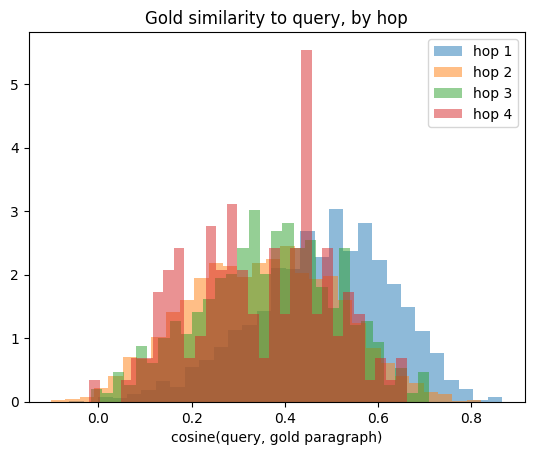

In [ ]:
# 1. The embedding gap by hop — your motivating figure
print(df.groupby("hop")["sim_query_gold"].mean())

# 2. How often Vector RAG misses a later-hop gold (outside top-5 of the 20)
print("hop>=2 gold outside top-5:", (df.query("hop>=2")["rank_among20"] > 5).mean())

# 3. Are consecutive golds embedding-neighbors? (do similarity edges chain them?)
print(df.groupby("hop")["sim_to_prev_gold"].mean())

# 4. Are consecutive golds linked by the bridge entity? (do lexical edges chain them?)
print("bridge entity present in later-hop gold:", df.query("hop>=2")["bridge_entity_in_gold"].mean())

for h, g in df.groupby("hop"):
    plt.hist(g["sim_query_gold"], bins=30, alpha=0.5, label=f"hop {h}", density=True)
plt.xlabel("cosine(query, gold paragraph)"); plt.legend(); plt.title("Gold similarity to query, by hop")
plt.show()